In [ ]:

!pip -q install cadquery-ocp torch-geometric


In [ ]:
#Uploading STEP file
from google.colab import files
from pathlib import Path
import shutil

# Directly targeting the local file as requested
STEP_PATH = Path("/content/Rectangle.STEP")

if not STEP_PATH.exists():
    raise FileNotFoundError(f"Could not find the CAD file at {STEP_PATH}. Please make sure it is uploaded to the Colab files pane.")

print("Selected CAD file:", STEP_PATH)
print("File size (MB):", round(STEP_PATH.stat().st_size / 1e6, 3))

Selected CAD file: /content/Rectangle.STEP
File size (MB): 0.049


In [ ]:
#Importing OCCT and inspect the model
from OCP.STEPControl import STEPControl_Reader
from OCP.IFSelect import IFSelect_RetDone
from OCP.TopAbs import TopAbs_FACE, TopAbs_EDGE, TopAbs_VERTEX
from OCP.TopExp import TopExp_Explorer

def count_shapes(shape, shape_type):
    explorer = TopExp_Explorer(shape, shape_type)
    count = 0
    while explorer.More():
        count += 1
        explorer.Next()
    return count

reader = STEPControl_Reader()
status = reader.ReadFile(str(STEP_PATH))

if status != IFSelect_RetDone:
    raise RuntimeError("OCCT could not read the STEP file.")

reader.TransferRoots()
shape = reader.OneShape()

if shape.IsNull():
    raise RuntimeError("The imported CAD shape is empty.")

print("STEP imported successfully!")
print("Faces:", count_shapes(shape, TopAbs_FACE))
print("Edges:", count_shapes(shape, TopAbs_EDGE))
print("Vertices:", count_shapes(shape, TopAbs_VERTEX))
print("Shape valid:", __import__(
    "OCP.BRepCheck", fromlist=["BRepCheck_Analyzer"]
).BRepCheck_Analyzer(shape).IsValid())


STEP imported successfully!
Faces: 20
Edges: 108
Vertices: 216
Shape valid: True


In [ ]:
#Converting the B-Rep into a graph
import csv
import json
import math
import numpy as np

from itertools import combinations
from pathlib import Path

from OCP.TopAbs import TopAbs_FACE, TopAbs_EDGE
from OCP.TopExp import TopExp, TopExp_Explorer
import OCP.TopoDS as OCP_TopoDS
from OCP.GeomAbs import (
    GeomAbs_Plane,
    GeomAbs_Cylinder,
    GeomAbs_Cone,
    GeomAbs_Sphere,
    GeomAbs_Torus,
    GeomAbs_BezierSurface,
    GeomAbs_BSplineSurface,
    GeomAbs_SurfaceOfRevolution,
    GeomAbs_SurfaceOfExtrusion,
    GeomAbs_OffsetSurface,
    GeomAbs_OtherSurface,
    GeomAbs_Line,
    GeomAbs_Circle,
    GeomAbs_Ellipse,
    GeomAbs_Hyperbola,
    GeomAbs_Parabola,
    GeomAbs_BezierCurve,
    GeomAbs_BSplineCurve,
    GeomAbs_OffsetCurve,
    GeomAbs_OtherCurve,
)
from OCP.BRepAdaptor import BRepAdaptor_Surface, BRepAdaptor_Curve
from OCP.GProp import GProp_GProps
from OCP.BRepGProp import BRepGProp

# Secure helper to downcast TopoDS_Shape to Face or Edge dynamically
def to_face(shape):
    try:
        return OCP_TopoDS.TopoDS.Face_s(shape)
    except AttributeError:
        return OCP_TopoDS.TopoDS.Face(shape)

def to_edge(shape):
    try:
        return OCP_TopoDS.TopoDS.Edge_s(shape)
    except AttributeError:
        return OCP_TopoDS.TopoDS.Edge(shape)

OUT = Path("/content/brep_graph_output")
OUT.mkdir(parents=True, exist_ok=True)

# Defining the categorical types
SURFACE_TYPES = [
    ("plane", GeomAbs_Plane),
    ("cylinder", GeomAbs_Cylinder),
    ("cone", GeomAbs_Cone),
    ("sphere", GeomAbs_Sphere),
    ("torus", GeomAbs_Torus),
    ("bezier_surface", GeomAbs_BezierSurface),
    ("bspline_surface", GeomAbs_BSplineSurface),
    ("surface_of_revolution", GeomAbs_SurfaceOfRevolution),
    ("surface_of_extrusion", GeomAbs_SurfaceOfExtrusion),
    ("offset_surface", GeomAbs_OffsetSurface),
    ("other_surface", GeomAbs_OtherSurface),
]

CURVE_TYPES = [
    ("line", GeomAbs_Line),
    ("circle", GeomAbs_Circle),
    ("ellipse", GeomAbs_Ellipse),
    ("hyperbola", GeomAbs_Hyperbola),
    ("parabola", GeomAbs_Parabola),
    ("bezier_curve", GeomAbs_BezierCurve),
    ("bspline_curve", GeomAbs_BSplineCurve),
    ("offset_curve", GeomAbs_OffsetCurve),
    ("other_curve", GeomAbs_OtherCurve),
]

def category_name(value, categories):
    for name, enum_value in categories:
        if value == enum_value:
            return name
    return categories[-1][0]

def xyz(point):
    return [float(point.X()), float(point.Y()), float(point.Z())]

def safe_float(value):
    value = float(value)
    return value if math.isfinite(value) else 0.0

# Enumerating all faces
faces = []
explorer = TopExp_Explorer(shape, TopAbs_FACE)

while explorer.More():
    faces.append(to_face(explorer.Current()))
    explorer.Next()

if not faces:
    raise ValueError("No faces were found in the imported CAD model.")

node_columns = (
    [f"surface_{name}" for name, _ in SURFACE_TYPES]
    + ["area", "centroid_x", "centroid_y", "centroid_z",
       "radius", "axis_x", "axis_y", "axis_z"]
)

face_rows = []
node_features = []

for face_id, face in enumerate(faces):
    adaptor = BRepAdaptor_Surface(face, True)
    surface_name = category_name(adaptor.GetType(), SURFACE_TYPES)

    props = GProp_GProps()
    BRepGProp.SurfaceProperties_s(face, props)
    area = safe_float(props.Mass())
    centroid = xyz(props.CentreOfMass())

    radius = 0.0
    axis = [0.0, 0.0, 0.0]

    try:
        if surface_name == "cylinder":
            cyl = adaptor.Cylinder()
            radius = safe_float(cyl.Radius())
            axis = xyz(cyl.Axis().Direction())
        elif surface_name == "cone":
            cone = adaptor.Cone()
            radius = safe_float(cone.RefRadius())
            axis = xyz(cone.Axis().Direction())
        elif surface_name == "sphere":
            radius = safe_float(adaptor.Sphere().Radius())
        elif surface_name == "torus":
            torus = adaptor.Torus()
            radius = safe_float(torus.MajorRadius())
    except Exception:
        pass

    one_hot = [
        1.0 if surface_name == name else 0.0
        for name, _ in SURFACE_TYPES
    ]

    features = one_hot + [area] + centroid + [radius] + axis
    node_features.append(features)

    face_rows.append({
        "face_id": face_id,
        "surface_type": surface_name,
        "area": area,
        "centroid_x": centroid[0],
        "centroid_y": centroid[1],
        "centroid_z": centroid[2],
        "radius": radius,
        "axis_x": axis[0],
        "axis_y": axis[1],
        "axis_z": axis[2],
    })

# Build a safe lookup using IsSame directly instead of custom hashes
edge_list = []

def get_or_register_edge(new_edge):
    for idx, existing_edge in enumerate(edge_list):
        if existing_edge.IsSame(new_edge):
            return idx + 1
    edge_list.append(new_edge)
    return len(edge_list)

# Map each topological edge to the faces that contain it
edge_to_faces = {}

for face_id, face in enumerate(faces):
    face_edge_ids = set()
    exp = TopExp_Explorer(face, TopAbs_EDGE)

    while exp.More():
        edge = to_edge(exp.Current())
        edge_id = get_or_register_edge(edge)
        face_edge_ids.add(edge_id)
        exp.Next()

    for edge_id in face_edge_ids:
        edge_to_faces.setdefault(edge_id, []).append(face_id)

# Extracting edge features
edge_columns = (
    [f"curve_{name}" for name, _ in CURVE_TYPES]
    + ["length", "centroid_x", "centroid_y", "centroid_z", "radius"]
)

edge_feature_cache = {}

def get_edge_features(edge_id):
    if edge_id in edge_feature_cache:
        return edge_feature_cache[edge_id]

    edge = edge_list[edge_id - 1]
    adaptor = BRepAdaptor_Curve(edge)
    curve_name = category_name(adaptor.GetType(), CURVE_TYPES)

    props = GProp_GProps()
    BRepGProp.LinearProperties_s(edge, props)

    length = safe_float(props.Mass())
    center = xyz(props.CentreOfMass())
    radius = 0.0

    try:
        if curve_name == "circle":
            radius = safe_float(adaptor.Circle().Radius())
        elif curve_name == "ellipse":
            radius = safe_float(adaptor.Ellipse().MajorRadius())
    except Exception:
        pass

    one_hot = [
        1.0 if curve_name == name else 0.0
        for name, _ in CURVE_TYPES
    ]

    feature = one_hot + [length] + center + [radius]

    row = {
        "topological_edge_id": edge_id,
        "curve_type": curve_name,
        "length": length,
        "centroid_x": center[0],
        "centroid_y": center[1],
        "centroid_z": center[2],
        "radius": radius,
    }

    edge_feature_cache[edge_id] = (feature, row)
    return feature, row

# Connecting adjacent faces
graph_rows = []
directed_pairs = []
directed_edge_features = []

for edge_id, incident_faces in edge_to_faces.items():
    unique_faces = sorted(set(incident_faces))

    if len(unique_faces) < 2:
        continue

    feature, edge_row = get_edge_features(edge_id)

    for face_a, face_b in combinations(unique_faces, 2):
        graph_rows.append({
            "face_i": face_a,
            "face_j": face_b,
            **edge_row,
        })

        directed_pairs.append((face_a, face_b))
        directed_edge_features.append(feature)

        directed_pairs.append((face_b, face_a))
        directed_edge_features.append(feature)

# Converting to NumPy arrays
x = np.asarray(node_features, dtype=np.float32)

if directed_pairs:
    edge_index = np.asarray(directed_pairs, dtype=np.int64).T
    edge_attr = np.asarray(directed_edge_features, dtype=np.float32)
else:
    edge_index = np.empty((2, 0), dtype=np.int64)
    edge_attr = np.empty((0, len(edge_columns)), dtype=np.float32)

assert x.shape == (len(faces), len(node_columns))
assert edge_index.shape[0] == 2
assert edge_attr.shape == (edge_index.shape[1], len(edge_columns))

print("B-Rep graph extraction complete")
print("Node feature matrix:", x.shape)
print("Directed edge index:", edge_index.shape)
print("Edge feature matrix:", edge_attr.shape)
print("Undirected face-pair records:", len(graph_rows))

B-Rep graph extraction complete
Node feature matrix: (20, 19)
Directed edge index: (2, 108)
Edge feature matrix: (108, 14)
Undirected face-pair records: 54


In [ ]:
#Saving the graph and preparing GNN training data
import pandas as pd
import torch
import zipfile

from torch_geometric.data import Data

# Saving descriptive face information
faces_df = pd.DataFrame(face_rows)
faces_df.to_csv(OUT / "faces.csv", index=False)

# Saving the full numerical node-feature matrix with column names
node_df = pd.DataFrame(x, columns=node_columns)
node_df.insert(0, "face_id", np.arange(len(faces)))
node_df.to_csv(OUT / "face_node_features.csv", index=False)

# Saving one row for each undirected face-pair/shared-edge record
graph_df = pd.DataFrame(
    graph_rows,
    columns=["face_i", "face_j"] + [
        "topological_edge_id", "curve_type", "length",
        "centroid_x", "centroid_y", "centroid_z", "radius"
    ]
)
graph_df.to_csv(OUT / "graph_edges.csv", index=False)

# Saving arrays for use in other ML frameworks
np.save(OUT / "node_features.npy", x)
np.save(OUT / "edge_index.npy", edge_index)
np.save(OUT / "edge_features.npy", edge_attr)

# Building a PyTorch Geometric graph
graph = Data(
    x=torch.tensor(x, dtype=torch.float32),
    edge_index=torch.tensor(edge_index, dtype=torch.long),
    edge_attr=torch.tensor(edge_attr, dtype=torch.float32),
    num_nodes=x.shape[0],
)

torch.save(graph, OUT / "graph_data.pt")

# Saving metadata so you know what each column means
metadata = {
    "source_file": STEP_PATH.name,
    "representation": "B-Rep face-adjacency graph",
    "node_definition": "One node per topological face",
    "connection_definition": (
        "Bidirectional connections between faces sharing "
        "a topological edge"
    ),
    "node_feature_columns": node_columns,
    "edge_feature_columns": edge_columns,
    "num_nodes": int(x.shape[0]),
    "num_directed_edges": int(edge_index.shape[1]),
    "num_undirected_face_pair_records": len(graph_rows),
    "node_feature_shape": list(x.shape),
    "edge_index_shape": list(edge_index.shape),
    "edge_feature_shape": list(edge_attr.shape),
    "labels_included": False,
    "note": (
        "Geometric features are raw and may need normalization. "
        "Feature-recognition labels must be supplied separately."
    ),
}

with open(OUT / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

#Bundling  the outputs into a ZIP archive
ZIP_PATH = Path("/content/brep_graph_dataset.zip")

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file_path in OUT.iterdir():
        if file_path.is_file():
            archive.write(file_path, arcname=file_path.name)

print("Files saved to:", OUT)
print("ZIP archive:", ZIP_PATH)
print("Graph summary:")
print(graph)
print("Node features:", tuple(graph.x.shape))
print("Edge index:", tuple(graph.edge_index.shape))
print("Edge attributes:", tuple(graph.edge_attr.shape))

Files saved to: /content/brep_graph_output
ZIP archive: /content/brep_graph_dataset.zip
Graph summary:
Data(x=[20, 19], edge_index=[2, 108], edge_attr=[108, 14], num_nodes=20)
Node features: (20, 19)
Edge index: (2, 108)
Edge attributes: (108, 14)


In [ ]:
#Downloading the results
from google.colab import files

files.download("/content/brep_graph_dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

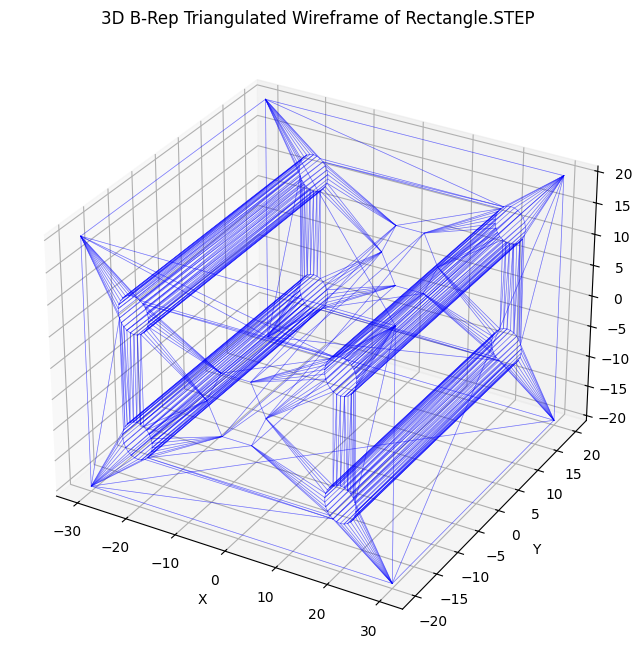

In [ ]:
#Converting the B-Rep into image
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from OCP.BRepMesh import BRepMesh_IncrementalMesh
from OCP.TopLoc import TopLoc_Location
from OCP.BRep import BRep_Tool
from OCP.TopAbs import TopAbs_FACE
from OCP.TopExp import TopExp_Explorer

# Secure helper to downcast TopoDS_Shape to Face dynamically
def to_face(shape):
    try:
        import OCP.TopoDS as OCP_TopoDS
        return OCP_TopoDS.TopoDS.Face_s(shape)
    except AttributeError:
        return OCP_TopoDS.TopoDS.Face(shape)

# Triangulate the shape to extract mesh nodes and display as a 3D plot
mesh = BRepMesh_IncrementalMesh(shape, 0.5)
mesh.Perform()

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

explorer = TopExp_Explorer(shape, TopAbs_FACE)
while explorer.More():
    face = to_face(explorer.Current())
    loc = TopLoc_Location()
    triangulation = BRep_Tool.Triangulation_s(face, loc)
    if triangulation:
        nb_triangles = triangulation.NbTriangles()
        trans = loc.Transformation()
        for i in range(1, nb_triangles + 1):
            tri = triangulation.Triangle(i)
            idx1, idx2, idx3 = tri.Value(1), tri.Value(2), tri.Value(3)

            p1 = triangulation.Node(idx1).Transformed(trans)
            p2 = triangulation.Node(idx2).Transformed(trans)
            p3 = triangulation.Node(idx3).Transformed(trans)

            x_coords = [p1.X(), p2.X(), p3.X(), p1.X()]
            y_coords = [p1.Y(), p2.Y(), p3.Y(), p1.Y()]
            z_coords = [p1.Z(), p2.Z(), p3.Z(), p1.Z()]

            ax.plot(x_coords, y_coords, z_coords, color='blue', alpha=0.3, linewidth=0.5)
    explorer.Next()

ax.set_title("3D B-Rep Triangulated Wireframe of Rectangle.STEP")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

In [ ]:
from torch_geometric.loader import DataLoader

# Wrap our single CAD graph in a list to represent a dataset
dataset = [graph]

# Initialize a PyG DataLoader with a batch size of 1
loader = DataLoader(dataset, batch_size=1, shuffle=False)

print("PyG DataLoader successfully created!")
print("Number of graphs in dataset:", len(loader.dataset))

# Demonstration of iterating through the loader
for batch in loader:
    print("\n--- Batch Details ---")
    print("Batch representation:", batch)
    print("Batch node feature shape (x):", batch.x.shape)
    print("Batch edge index shape (edge_index):", batch.edge_index.shape)
    print("Batch edge feature shape (edge_attr):", batch.edge_attr.shape)
    print("Batch vector mapping nodes to graphs (batch):", batch.batch.shape)

PyG DataLoader successfully created!
Number of graphs in dataset: 1

--- Batch Details ---
Batch representation: DataBatch(x=[20, 19], edge_index=[2, 108], edge_attr=[108, 14], num_nodes=20, batch=[20], ptr=[2])
Batch node feature shape (x): torch.Size([20, 19])
Batch edge index shape (edge_index): torch.Size([2, 108])
Batch edge feature shape (edge_attr): torch.Size([108, 14])
Batch vector mapping nodes to graphs (batch): torch.Size([20])


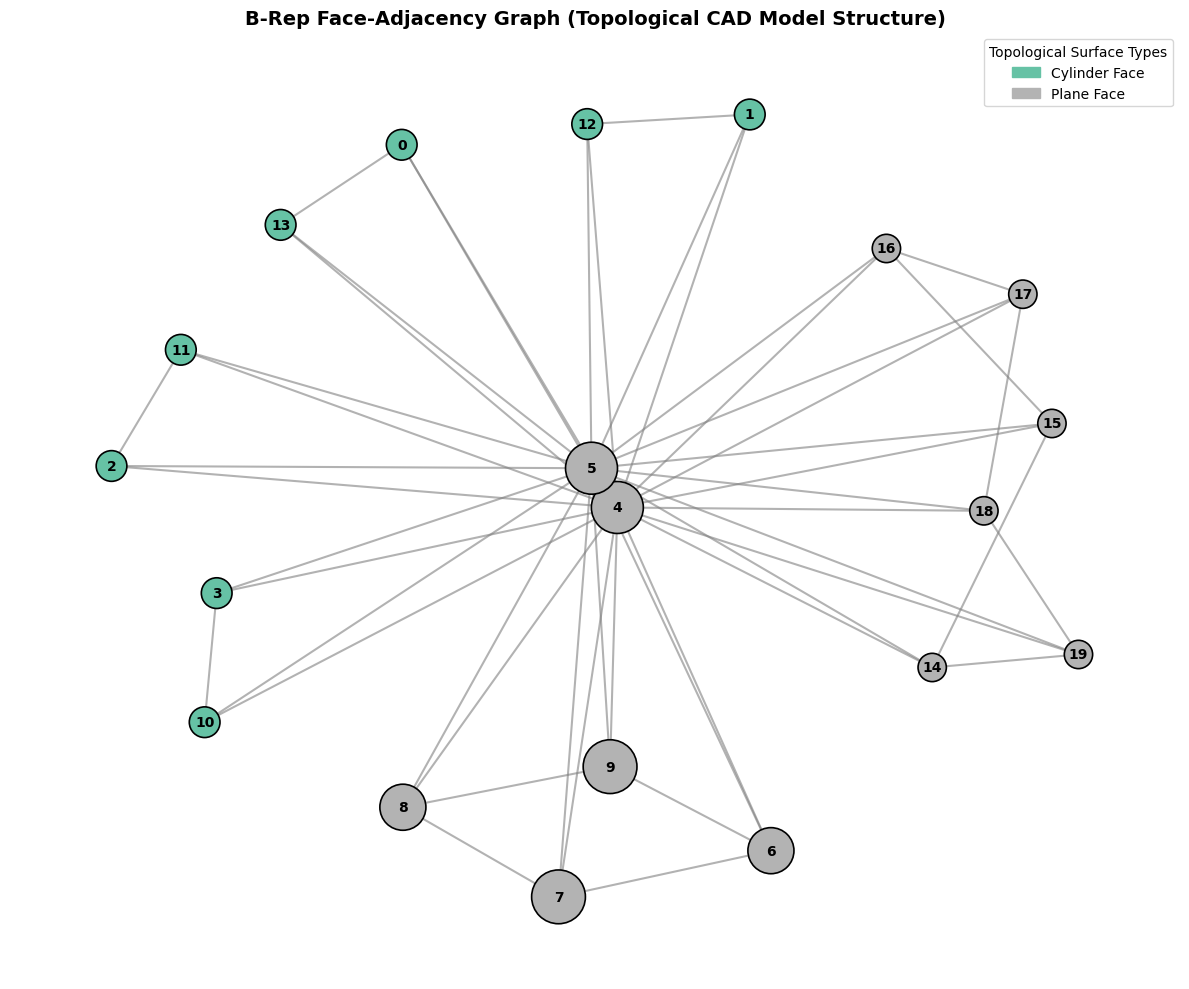

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import matplotlib

# Retrieve data from our generated DataFrames
nodes_info = faces_df.copy()
edges_info = graph_df.copy()

# Create an undirected NetworkX graph
G = nx.Graph()

# Add nodes with their attributes
for _, row in nodes_info.iterrows():
    G.add_node(
        int(row['face_id']),
        surface_type=row['surface_type'],
        area=float(row['area']),
        centroid=(float(row['centroid_x']), float(row['centroid_y']), float(row['centroid_z']))
    )

# Add edges
for _, row in edges_info.iterrows():
    G.add_edge(int(row['face_i']), int(row['face_j']), curve_type=row['curve_type'])

# Setup node colors based on surface type mapping using the updated Colormap API
unique_types = sorted(list(nodes_info['surface_type'].unique()))
color_palette = matplotlib.colormaps['Set2'].resampled(len(unique_types))
type_to_color = {stype: color_palette(i) for i, stype in enumerate(unique_types)}

node_colors = [type_to_color[G.nodes[node]['surface_type']] for node in G.nodes()]

# Scale node size based on area (normalized for display)
areas = np.array([G.nodes[node]['area'] for node in G.nodes()])
max_area = areas.max() if areas.size > 0 else 1.0
# Scale nodes to a visually pleasing size range [300, 1500]
node_sizes = 300 + 1200 * (areas / max_area)

# Draw layout using a spring layout for clean spacing
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42, k=0.5)

# Draw topological connections - corrected typo here from 'x' to 'nx'
nx.draw_networkx_edges(G, pos, width=1.5, edge_color='gray', alpha=0.6)

# Draw the faces (nodes)
nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=node_sizes,
    edgecolors='black',
    linewidths=1.2
)

# Label with topological Face ID
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold', font_color='black')

# Construct legend
legend_handles = [
    mpatches.Patch(color=color, label=f"{stype.capitalize()} Face")
    for stype, color in type_to_color.items()
]
plt.legend(handles=legend_handles, loc='upper right', title="Topological Surface Types", frameon=True)

plt.title("B-Rep Face-Adjacency Graph (Topological CAD Model Structure)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

### Graph Feature Map

Below is the map showing what each index of your node and edge feature tensors represents in the model dataset:

#### Node Feature Vector (19 Dimensions)
* **Indices 0-10 (One-Hot Surface Type):** `Plane`, `Cylinder`, `Cone`, `Sphere`, `Torus`, `BezierSurface`, `BSplineSurface`, `RevolutionSurface`, `ExtrusionSurface`, `OffsetSurface`, `OtherSurface`
* **Index 11:** Surface Area
* **Indices 12-14:** Face Centroid Coord $(X, Y, Z)$
* **Index 15:** Surface Radius (e.g. for Cylinders/Spheres, otherwise `0.0`)
* **Indices 16-18:** Direction Vector Axis $(X, Y, Z)$

#### Edge Feature Vector (14 Dimensions)
* **Indices 0-8 (One-Hot Curve Type):** `Line`, `Circle`, `Ellipse`, `Hyperbola`, `Parabola`, `BezierCurve`, `BSplineCurve`, `OffsetCurve`, `OtherCurve`
* **Index 9:** Edge Curve Length
* **Indices 10-12:** Edge Centroid Coord $(X, Y, Z)$
* **Index 13:** Curve Radius (e.g. for Circles/Ellipses, otherwise `0.0`)

In [ ]:
# Summarize features in beautiful dataframes for instant inspection
import pandas as pd

print("=== EXTRACTED NODE (FACE) FEATURES (First 5 nodes) ===")
node_feat_df = pd.DataFrame(graph.x.numpy(), columns=node_columns)
display(node_feat_df.head())

print("\n=== EXTRACTED EDGE (BOUNDARY) FEATURES (First 5 edges) ===")
edge_feat_df = pd.DataFrame(graph.edge_attr.numpy(), columns=edge_columns)
display(edge_feat_df.head())

=== EXTRACTED NODE (FACE) FEATURES (First 5 nodes) ===


,surface_plane,surface_cylinder,surface_cone,surface_sphere,surface_torus,surface_bezier_surface,surface_bspline_surface,surface_surface_of_revolution,surface_surface_of_extrusion,surface_offset_surface,surface_other_surface,area,centroid_x,centroid_y,centroid_z,radius,axis_x,axis_y,axis_z
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,376.991119,-2.190986e+01,9.659462e-16,1.000000e+01,3.0,-0.0,-1.0,-0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,376.991119,1.809014e+01,9.659462e-16,1.000000e+01,3.0,-0.0,-1.0,-0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,376.991119,1.809014e+01,9.659462e-16,-1.000000e+01,3.0,-0.0,-1.0,-0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,376.991119,-2.190986e+01,9.659462e-16,-1.000000e+01,3.0,-0.0,-1.0,-0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2200.300049,-3.565608e-15,2.000000e+01,-3.679365e-15,0.0,0.0,0.0,0.0



=== EXTRACTED EDGE (BOUNDARY) FEATURES (First 5 edges) ===


,curve_line,curve_circle,curve_ellipse,curve_hyperbola,curve_parabola,curve_bezier_curve,curve_bspline_curve,curve_offset_curve,curve_other_curve,length,centroid_x,centroid_y,centroid_z,radius
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.000000,-20.000000,-8.881784e-16,7.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.000000,-20.000000,-8.881784e-16,7.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.424778,-21.909859,-2.000000e+01,10.0,3.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.424778,-21.909859,-2.000000e+01,10.0,3.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.000000,-20.000000,-8.881784e-16,13.0,0.0


In [ ]:
# Build and display a clean face-adjacency list
face_adjacency_df = pd.DataFrame(graph_rows)

# Reorder columns to make adjacency clear
columns_order = ['face_i', 'face_j', 'topological_edge_id', 'curve_type', 'length', 'radius']
face_adjacency_df = face_adjacency_df[columns_order]

print("=== FACE ADJACENCY RELATIONS (Shared Boundaries) ===")
display(face_adjacency_df.head(15))

=== FACE ADJACENCY RELATIONS (Shared Boundaries) ===


,face_i,face_j,topological_edge_id,curve_type,length,radius
0,0,13,1,line,40.000000,0.0
1,0,5,2,circle,9.424778,3.0
2,0,13,3,line,40.000000,0.0
3,0,4,4,circle,9.424778,3.0
4,1,4,8,circle,9.424778,3.0
5,1,12,5,line,40.000000,0.0
6,1,5,6,circle,9.424778,3.0
7,1,12,7,line,40.000000,0.0
8,2,11,9,line,40.000000,0.0
9,2,5,10,circle,9.424778,3.0


In [ ]:
import pandas as pd

# Map face IDs to their surface types for both face_i and face_j
surface_map = faces_df.set_index('face_id')['surface_type'].to_dict()

# Create a copy of the adjacency dataframe
adjacency_analysis_df = face_adjacency_df.copy()

# Inject surface types to make connection types clear
adjacency_analysis_df.insert(1, 'face_i_type', adjacency_analysis_df['face_i'].map(surface_map))
adjacency_analysis_df.insert(3, 'face_j_type', adjacency_analysis_df['face_j'].map(surface_map))

# Classify the type of connection (e.g., plane-cylinder, plane-plane)
def get_connection_type(row):
    types = sorted([row['face_i_type'], row['face_j_type']])
    return f"{types[0]} <-> {types[1]}"

adjacency_analysis_df['connection_interface'] = adjacency_analysis_df.apply(get_connection_type, axis=1)

print("=== SURFACE ADJACENCY RELATIONSHIPS WITH GEOMETRIC SURFACES ===")
display(adjacency_analysis_df.head(15))

print("\n=== FREQUENCY OF INTERFACE CONNECTIONS ===")
interface_counts = adjacency_analysis_df['connection_interface'].value_counts().to_frame('count')
display(interface_counts)

=== SURFACE ADJACENCY RELATIONSHIPS WITH GEOMETRIC SURFACES ===


,face_i,face_i_type,face_j,face_j_type,topological_edge_id,curve_type,length,radius,connection_interface
0,0,cylinder,13,cylinder,1,line,40.000000,0.0,cylinder <-> cylinder
1,0,cylinder,5,plane,2,circle,9.424778,3.0,cylinder <-> plane
2,0,cylinder,13,cylinder,3,line,40.000000,0.0,cylinder <-> cylinder
3,0,cylinder,4,plane,4,circle,9.424778,3.0,cylinder <-> plane
4,1,cylinder,4,plane,8,circle,9.424778,3.0,cylinder <-> plane
5,1,cylinder,12,cylinder,5,line,40.000000,0.0,cylinder <-> cylinder
6,1,cylinder,5,plane,6,circle,9.424778,3.0,cylinder <-> plane
7,1,cylinder,12,cylinder,7,line,40.000000,0.0,cylinder <-> cylinder
8,2,cylinder,11,cylinder,9,line,40.000000,0.0,cylinder <-> cylinder
9,2,cylinder,5,plane,10,circle,9.424778,3.0,cylinder <-> plane



=== FREQUENCY OF INTERFACE CONNECTIONS ===


,count
connection_interface,
plane <-> plane,30
cylinder <-> plane,16
cylinder <-> cylinder,8


In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data
import pandas as pd
import numpy as np

# --- Step 1: Add Face Labels (Target Classes) ---
# Let's map: Cylinder -> Class 0, Plane -> Class 1
# In a real pipeline, these could be custom labels like Holes, Chamfers, Flanges, etc.
class_mapping = {'cylinder': 0, 'plane': 1}
y_labels = [class_mapping[t] for t in faces_df['surface_type']]
y_tensor = torch.tensor(y_labels, dtype=torch.long)

# Create train/test mask (70% train, 30% test)
np.random.seed(42)
num_nodes = len(faces_df)
indices = np.random.permutation(num_nodes)
train_size = int(0.7 * num_nodes)

train_mask = np.zeros(num_nodes, dtype=bool)
test_mask = np.zeros(num_nodes, dtype=bool)
train_mask[indices[:train_size]] = True
test_mask[indices[train_size:]] = True

# Update our PyG graph object with target labels and masks
graph.y = y_tensor
graph.train_mask = torch.tensor(train_mask, dtype=torch.bool)
graph.test_mask = torch.tensor(test_mask, dtype=torch.bool)

# --- Step 2: Define GNN Architecture ---
class FaceClassifierGCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(FaceClassifierGCN, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.1, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

# Instantiate GCN model
in_dim = graph.x.shape[1]   # 19 features
hidden_dim = 16
out_dim = 2                # 2 classes: Cylinder vs Plane

model = FaceClassifierGCN(in_channels=in_dim, hidden_channels=hidden_dim, out_channels=out_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

# --- Step 3: Train the GNN ---
print("=== TRAINING GNN FOR FACE CLASSIFICATION ===")
model.train()
for epoch in range(1, 101):
    optimizer.zero_grad()
    out = model(graph.x, graph.edge_index)
    loss = F.nll_loss(out[graph.train_mask], graph.y[graph.train_mask])
    loss.backward()
    optimizer.step()

    if epoch % 10 == 0:
        # Calculate training accuracy
        pred = out.argmax(dim=1)
        correct = pred[graph.train_mask] == graph.y[graph.train_mask]
        acc = int(correct.sum()) / int(graph.train_mask.sum())
        print(f"Epoch {epoch:3d} | Loss: {loss.item():.4f} | Train Acc: {acc * 100:.1f}%")

# --- Step 4: Evaluate Model ---
model.eval()
with torch.no_grad():
    out = model(graph.x, graph.edge_index)
    pred = out.argmax(dim=1)
    test_correct = pred[graph.test_mask] == graph.y[graph.test_mask]
    test_acc = int(test_correct.sum()) / int(graph.test_mask.sum())

print("\n=== EVALUATION RESULTS ===")
print(f"Test Accuracy: {test_acc * 100:.1f}%")

# Display predictions alongside ground truths
results_df = pd.DataFrame({
    'Face ID': faces_df['face_id'],
    'Surface Type': faces_df['surface_type'],
    'Actual Class': graph.y.numpy(),
    'Predicted Class': pred.numpy(),
    'Train Mask': graph.train_mask.numpy()
})
display(results_df)

=== TRAINING GNN FOR FACE CLASSIFICATION ===
Epoch  10 | Loss: 19.3395 | Train Acc: 42.9%
Epoch  20 | Loss: 2.9654 | Train Acc: 78.6%
Epoch  30 | Loss: 4.7498 | Train Acc: 64.3%
Epoch  40 | Loss: 5.3797 | Train Acc: 57.1%
Epoch  50 | Loss: 6.8886 | Train Acc: 35.7%
Epoch  60 | Loss: 4.6898 | Train Acc: 50.0%
Epoch  70 | Loss: 14.4701 | Train Acc: 64.3%
Epoch  80 | Loss: 7.3209 | Train Acc: 28.6%
Epoch  90 | Loss: 11.6658 | Train Acc: 50.0%
Epoch 100 | Loss: 17.1081 | Train Acc: 57.1%

=== EVALUATION RESULTS ===
Test Accuracy: 66.7%


,Face ID,Surface Type,Actual Class,Predicted Class,Train Mask
0,0,cylinder,0,1,True
1,1,cylinder,0,1,True
2,2,cylinder,0,1,True
3,3,cylinder,0,1,True
4,4,plane,1,1,False
5,5,plane,1,1,True
6,6,plane,1,1,False
7,7,plane,1,1,False
8,8,plane,1,1,True
9,9,plane,1,1,True


In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
import pandas as pd
import numpy as np

# --- Step 1: Feature Normalization (Z-score) ---
# Columns 0 to 10 are binary/one-hot surface types (already scaled)
# Columns 11 to 18 are continuous features (Area, Centroids, Radius, Axis)
x_raw = graph.x.numpy()
x_normalized = x_raw.copy()

for col_idx in range(11, 19):
    col_data = x_raw[:, col_idx]
    mean = np.mean(col_data)
    std = np.std(col_data)
    if std > 1e-6:
        x_normalized[:, col_idx] = (col_data - mean) / std
    else:
        x_normalized[:, col_idx] = 0.0

# Update graph representation with normalized features
graph.x = torch.tensor(x_normalized, dtype=torch.float32)

# --- Step 2: Define GNN ---
class NormalizedFaceGCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(NormalizedFaceGCN, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.1, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

# Re-instantiate model & optimizer with a smaller learning rate for stability
model_norm = NormalizedFaceGCN(in_channels=19, hidden_channels=16, out_channels=2)
optimizer = torch.optim.Adam(model_norm.parameters(), lr=0.01, weight_decay=5e-4)

# --- Step 3: Train ---
print("=== TRAINING GNN WITH NORMALIZED FEATURES ===")
model_norm.train()
for epoch in range(1, 151):
    optimizer.zero_grad()
    out = model_norm(graph.x, graph.edge_index)
    loss = F.nll_loss(out[graph.train_mask], graph.y[graph.train_mask])
    loss.backward()
    optimizer.step()

    if epoch % 15 == 0:
        pred = out.argmax(dim=1)
        correct = pred[graph.train_mask] == graph.y[graph.train_mask]
        acc = int(correct.sum()) / int(graph.train_mask.sum())
        print(f"Epoch {epoch:3d} | Loss: {loss.item():.4f} | Train Acc: {acc * 100:.1f}%")

# --- Step 4: Evaluate ---
model_norm.eval()
with torch.no_grad():
    out = model_norm(graph.x, graph.edge_index)
    pred = out.argmax(dim=1)
    test_correct = pred[graph.test_mask] == graph.y[graph.test_mask]
    test_acc = int(test_correct.sum()) / int(graph.test_mask.sum())

print("\n=== EVALUATION RESULTS (WITH NORMALIZED FEATURES) ===")
print(f"Test Accuracy: {test_acc * 100:.1f}%")

# Display predictions alongside ground truths
results_norm_df = pd.DataFrame({
    'Face ID': faces_df['face_id'],
    'Surface Type': faces_df['surface_type'],
    'Actual Class': graph.y.numpy(),
    'Predicted Class': pred.numpy(),
    'Train Mask': graph.train_mask.numpy()
})
display(results_norm_df)

=== TRAINING GNN WITH NORMALIZED FEATURES ===
Epoch  15 | Loss: 0.2698 | Train Acc: 100.0%
Epoch  30 | Loss: 0.0772 | Train Acc: 100.0%
Epoch  45 | Loss: 0.0268 | Train Acc: 100.0%
Epoch  60 | Loss: 0.0101 | Train Acc: 100.0%
Epoch  75 | Loss: 0.0061 | Train Acc: 100.0%
Epoch  90 | Loss: 0.0039 | Train Acc: 100.0%
Epoch 105 | Loss: 0.0023 | Train Acc: 100.0%
Epoch 120 | Loss: 0.0042 | Train Acc: 100.0%
Epoch 135 | Loss: 0.0025 | Train Acc: 100.0%
Epoch 150 | Loss: 0.0022 | Train Acc: 100.0%

=== EVALUATION RESULTS (WITH NORMALIZED FEATURES) ===
Test Accuracy: 100.0%


,Face ID,Surface Type,Actual Class,Predicted Class,Train Mask
0,0,cylinder,0,0,True
1,1,cylinder,0,0,True
2,2,cylinder,0,0,True
3,3,cylinder,0,0,True
4,4,plane,1,1,False
5,5,plane,1,1,True
6,6,plane,1,1,False
7,7,plane,1,1,False
8,8,plane,1,1,True
9,9,plane,1,1,True


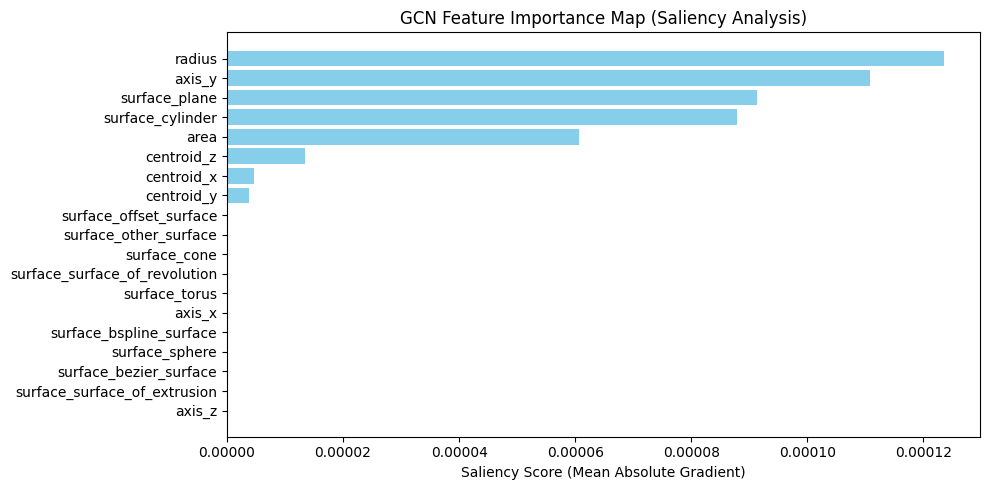

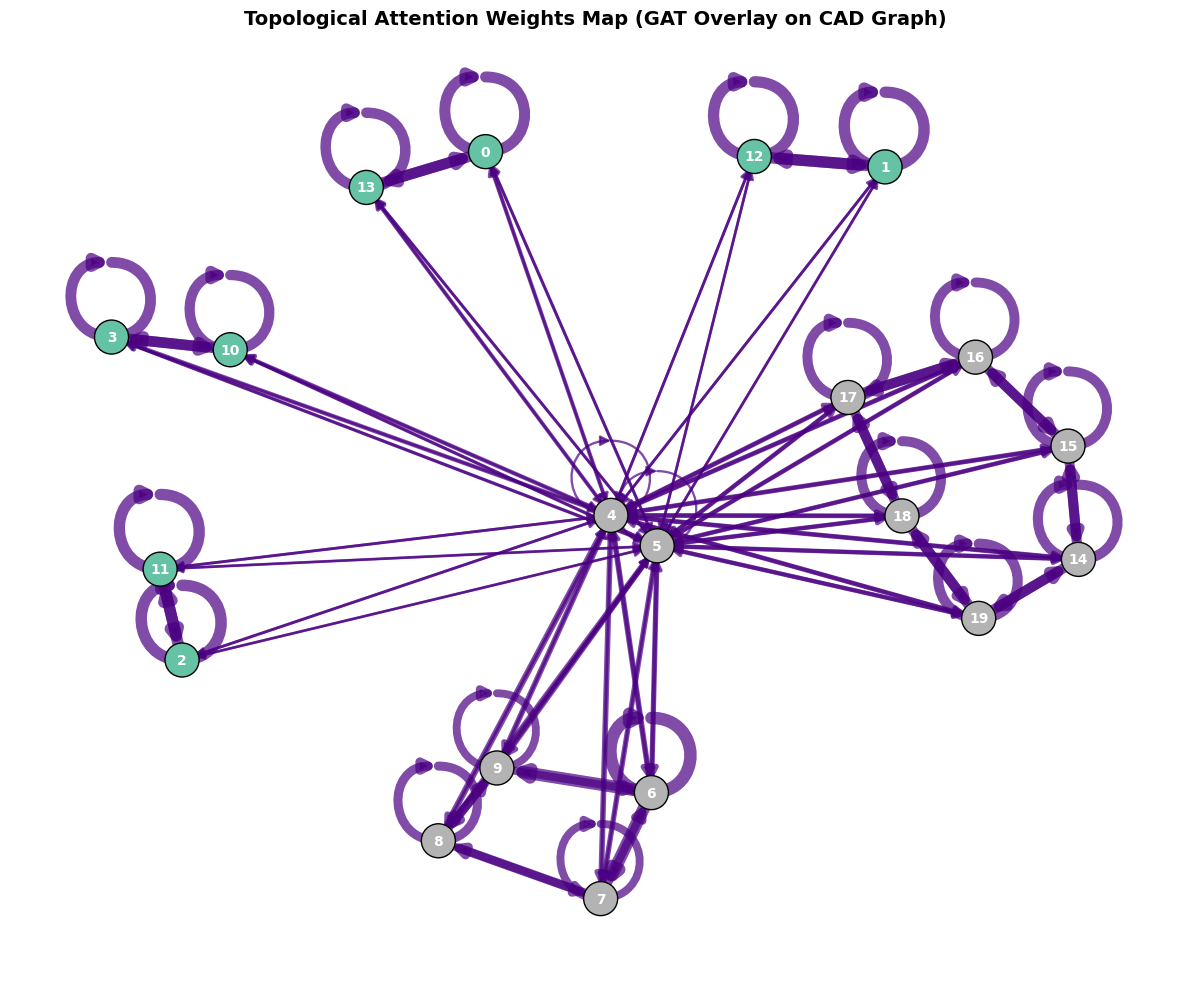

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import torch.nn.functional as F
from torch_geometric.nn import GATConv

# --- 1. GCN Feature Importance via Gradient Saliency ---
model_norm.eval()
input_x = graph.x.clone().detach().requires_grad_(True)
out = model_norm(input_x, graph.edge_index)

# Target class predictions
preds = out.argmax(dim=1)
loss = F.nll_loss(out, preds)
loss.backward()

# Feature importance is the average absolute gradient value for each feature column
saliency = input_x.grad.abs().mean(dim=0).numpy()
feature_names = np.array(node_columns)

# Sort for visualization
sort_idx = np.argsort(saliency)
plt.figure(figsize=(10, 5))
plt.barh(feature_names[sort_idx], saliency[sort_idx], color='skyblue')
plt.xlabel("Saliency Score (Mean Absolute Gradient)")
plt.title("GCN Feature Importance Map (Saliency Analysis)")
plt.tight_layout()
plt.show()

# --- 2. GAT Training to extract Edge Attention Weights (Fixed API) ---
class FaceGAT(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(FaceGAT, self).__init__()
        # GATConv constructor does not take return_attention_weights in newer PyG versions
        self.gat1 = GATConv(in_channels, hidden_channels, heads=2)
        self.gat2 = GATConv(hidden_channels * 2, out_channels, heads=1)

    def forward(self, x, edge_index):
        # Pass return_attention_weights directly to the forward call of GATConv
        x, edge_att1 = self.gat1(x, edge_index, return_attention_weights=True)
        x = F.relu(x)
        x, edge_att2 = self.gat2(x, edge_index, return_attention_weights=True)
        return F.log_softmax(x, dim=1), edge_att2

gat_model = FaceGAT(in_channels=19, hidden_channels=8, out_channels=2)
gat_optimizer = torch.optim.Adam(gat_model.parameters(), lr=0.01, weight_decay=5e-4)

# Train GAT
gat_model.train()
for epoch in range(1, 151):
    gat_optimizer.zero_grad()
    out_gat, _ = gat_model(graph.x, graph.edge_index)
    loss = F.nll_loss(out_gat[graph.train_mask], graph.y[graph.train_mask])
    loss.backward()
    gat_optimizer.step()

# Evaluate and Extract attention weights
gat_model.eval()
with torch.no_grad():
    out_gat, (att_edges, att_weights) = gat_model(graph.x, graph.edge_index)
    # Average attention weights across GAT heads
    avg_att_weights = att_weights.mean(dim=1).squeeze().numpy()

# --- 3. Visualize Topological GAT Attention on NetworkX ---
G_att = nx.DiGraph()
for i in range(len(faces_df)):
    G_att.add_node(i, surface_type=faces_df.loc[i, 'surface_type'])

# Add edges with averaged attention weight attributes
for idx in range(att_edges.shape[1]):
    u = int(att_edges[0, idx])
    v = int(att_edges[1, idx])
    w = float(avg_att_weights[idx])
    G_att.add_edge(u, v, weight=w)

# Plot the graph with weighted edges
plt.figure(figsize=(12, 10))
pos_att = nx.spring_layout(G_att, seed=42)

# Normalize edge widths based on attention weight
weights = [G_att[u][v]['weight'] for u, v in G_att.edges()]
max_w = max(weights) if weights else 1.0
normalized_widths = [1.0 + 8.0 * (w / max_w) for w in weights]

nx.draw_networkx_nodes(G_att, pos_att, node_color=node_colors, node_size=600, edgecolors='black')
nx.draw_networkx_edges(G_att, pos_att, width=normalized_widths, edge_color='indigo', alpha=0.7, arrowsize=15)
nx.draw_networkx_labels(G_att, pos_att, font_size=10, font_weight='bold', font_color='white')

plt.title("Topological Attention Weights Map (GAT Overlay on CAD Graph)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()